**Wojciech Olejnik**

# Sieci neuronowe wielowarstwowe

Celem ćwiczenia jest badanie działania sieci neuronowych w zastosowaniu do zadania klasyfkacji.Do badań wykorzysatno klasę **_MLPClassifier_** z pakietu **_sklearn_**

# Przygotowanie danych do badań

In [7]:
import matplotlib.pyplot as plt
from datasets import make_checkerboard, make_spiral, make_halfmoon
from sklearn.datasets import make_circles
from sklearn.neural_network import MLPClassifier
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pandas as pd


import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

**Szachownica**

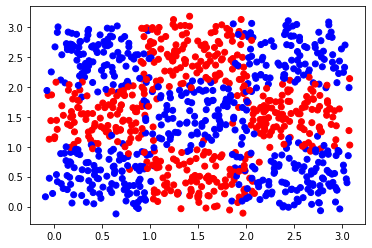

In [3]:
x, y = make_checkerboard(1000,3, noise=.1)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

**Półksiężce**

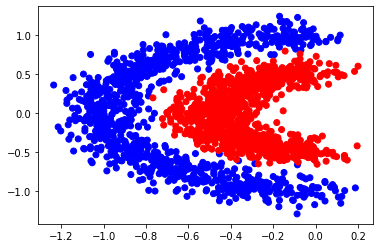

In [4]:
x, y = make_halfmoon(1000, 0.1)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

**Okręgi**

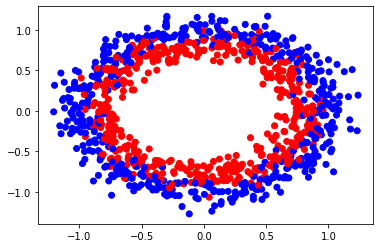

In [5]:
x, y = make_circles(1000, noise=0.1)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

**Zagnieżdżone spirale**

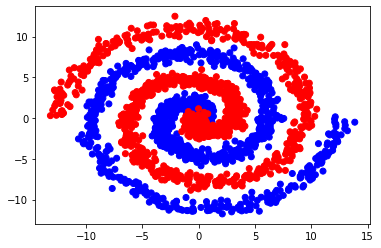

In [6]:
x, y = make_spiral(1000, noise=.5)
plt.scatter(x[:, 0], x[:, 1], c=y, cmap="bwr")
plt.show()

# Tworzenie modelu

Przygotowanie danych

In [63]:
# https://www.python-course.eu/neural_networks_with_scikit.php
X, y = make_circles(1000, noise=0.1)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=10)

Tworzenie modelu 

In [36]:
h=2
K=10
alpha=1e-54
hidden_layer_sizes = [K] * h
clf = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, solver="adam" alpha=alpha)

In [37]:
clf.fit(X_train, y_train)

MLPClassifier(alpha=1e-54, hidden_layer_sizes=[10, 10])

In [43]:
y_true = y_test
y_pred = clf.predict(X_test)

acc = accuracy_score(y_true, y_pred)
print(f'acc => {acc}')

f1 = f1_score(y_true, y_pred)
print(f'f1 => {f1}')

y_score = clf.predict_proba(X_test)
auc = roc_auc_score(y_true, y_score[:, 1])
print(f'accuracy => {auc}')

acc_train = accuracy_score(y_train, clf.predict(X_train))
print(f'accuracy_train => {acc_train}')

acc => 0.796
f1 => 0.801556420233463
accuracy => 0.8572275641025642
accuracy_train => 0.818


In [56]:
t1_fit = time.time()
clf.fit(
    X_train, y_train
)  # this is done two times. But this separation might be better for testing.
t_fit = time.time() - t1_fit

t1_pred = time.time()
clf.predict(X_test)
t_pred = time.time() - t1_pred
print(f"Czas uczenia: {t_fit}")
print(f"Czas predykcji: {t_pred}")
n_params = sum([a.size for a in clf.coefs_]) + sum([a.size for a in clf.intercepts_])
print(f"Liczba parametrow sieci: {n_params}")

Czas uczenia: 0.2913651466369629
Czas predykcji: 0.0003161430358886719
Liczba parametrow sieci: 151


Wizualizacji granic decyzji

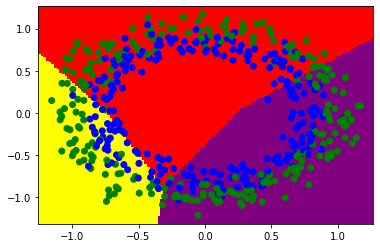

In [72]:
# Plot decision
plt.figure()

# Decision boundary
x_min, x_max = X_test[:, 0].min() - 0.1, X_test[:, 0].max() + 0.1
y_min, y_max = X_test[:, 1].min() - 0.1, X_test[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

cmap_light = ListedColormap(["red", "purple", "yellow"])
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

# Plot class
colors = ["green" if item == 0 else "blue" for item in y_test]
plt.scatter(X_test[:, 0], X_test[:, 1], c=colors)
plt.show()

Wizualizacja sieci dwuwarstwowej. Aby cztelnie przedstawić tablice decyzyjne oraz separacje danych, za pomoca prostych przygotowano następujacy zestaw danych

In [73]:
X_2, y_2 = datasets.make_blobs(n_samples=1000, centers=3, random_state=8)
clf_2 = MLPClassifier(hidden_layer_sizes=2)

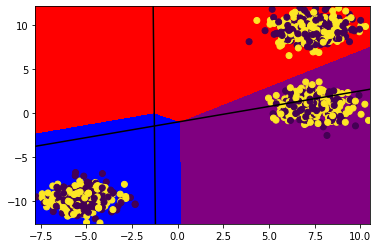

In [90]:
clf.fit(X_2, y_2)

# Plot
plt.figure()

x_min, x_max = X_2[:, 0].min() - 0.1, X_2[:, 0].max() + 0.1
y_min, y_max = X_2[:, 1].min() - 0.1, X_2[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

cmap_light = ListedColormap(["red", "purple", "blue"])
plt.pcolormesh(xx, yy, Z, cmap=cmap_light)


plt.scatter(X_2[:, 0], X_2[:, 1], c=y)
xmin, xmax = plt.xlim()
ymin, ymax = plt.ylim()
for i in range(len(clf.intercepts_[0])):
    w = clf.coefs_[0][:, i]
    a = -w[0] / w[1]
    xx = np.linspace(xmin, xmax)
    yy = a * xx - (clf.intercepts_[0][i]) / w[1]

    # Plot the hyperplane
    plt.plot(xx, yy, "k-")

plt.ylim(ymin, ymax)
plt.show()

# Część eksperymentalna

**Eksperyment dla liczby warstw h = 1,2,3,4**

In [22]:
def expertiment_layers():
#     X, y = make_circles(n_samples=500, noise=0.05)
    X, y = make_checkerboard(1000,3, noise=.1)
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=42)

    params = [
            {"h": 1, "K": 10},
            {"h": 2, "K": 50},
            {"h": 3, "K": 30},
            {"h": 5, "K": 20},
            {"h": 10, "K": 10},
    ]
    data = {
        "layers": [],
        "neurons_in_layer": [],
        "acc": [],
        "acc_train": [],
        "f1": [],
        "auc": [],
        "n_params": [],
        "t_fit": [],
        "t_pred": [],
    }

    for p in params:
        hidden_layer_sizes = p["h"] * p["K"]
        clf = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, solver="adam", alpha=1e-2)

        clf.fit(X_train, y_train)

        y_true = y_test
        y_pred = clf.predict(X_test)

        acc = accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)

        y_score = clf.predict_proba(X_test)
        auc = roc_auc_score(y_true, y_score[:, 1])

        acc_train = accuracy_score(y_train, clf.predict(X_train))

        n_params = sum([a.size for a in clf.coefs_]) + sum([a.size for a in clf.intercepts_])

        t1_fit = time.time()
        clf.fit(X_train, y_train)  
        t_fit = time.time() - t1_fit

        t1_pred = time.time()
        clf.predict(X_test)
        t_pred = time.time() - t1_pred

        data["layers"].append(p["h"])
        data["neurons_in_layer"].append(p["K"])
        data["acc"].append(acc)
        data["acc_train"].append(acc_train)
        data["f1"].append(f1)
        data["auc"].append(auc)
        data["n_params"].append(n_params)
        data["t_fit"].append(t_fit)
        data["t_pred"].append(t_pred)
        
    return data

   layers  neurons_in_layer    acc  acc_train        f1       auc  n_params  \
0       1                10  0.448      0.536  0.330097  0.394551        41   
1       2                50  0.732      0.780  0.728745  0.848782       401   
2       3                30  0.604      0.708  0.668896  0.798333       361   
3       5                20  0.788      0.840  0.778243  0.875769       401   
4      10                10  0.788      0.848  0.793774  0.883333       401   

      t_fit    t_pred  
0  0.150322  0.000234  
1  0.360473  0.000442  
2  0.386258  0.000431  
3  0.356195  0.000424  
4  0.409830  0.000439  


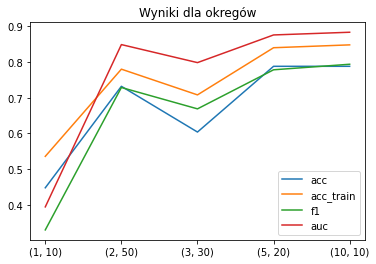

In [21]:
exp_data = expertiment_layers()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc", "acc_train", "f1", "auc"]].plot()
xticklabels = ["(1, 10)", "(2, 50)", "(3, 30)", "(5, 20)", "(10, 10)"]
plt.title('Wyniki dla okregów')
plt.xticks([0, 1, 2, 3, 4], xticklabels)
plt.show()

   layers  neurons_in_layer    acc  acc_train        f1       auc  n_params  \
0       1                10  0.530      0.578  0.000000  0.500249        41   
1       2                50  0.608      0.654  0.512438  0.741068       401   
2       3                30  0.574      0.598  0.432000  0.736813       361   
3       5                20  0.592      0.628  0.468750  0.736218       401   
4      10                10  0.612      0.644  0.478495  0.742834       401   

      t_fit    t_pred  
0  0.281266  0.000246  
1  0.597535  0.000576  
2  0.566322  0.000549  
3  0.587473  0.000611  
4  0.587456  0.000581  


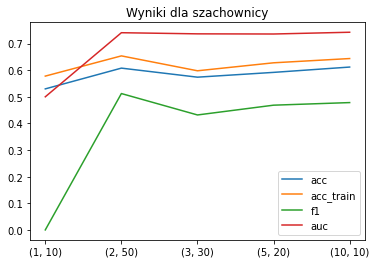

In [23]:
exp_data = expertiment_layers()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc", "acc_train", "f1", "auc"]].plot()
xticklabels = ["(1, 10)", "(2, 50)", "(3, 30)", "(5, 20)", "(10, 10)"]
plt.title('Wyniki dla szachownicy')
plt.xticks([0, 1, 2, 3, 4], xticklabels)
plt.show()

**Wniosek :** _Zwiększanie liczby warstw sieci większa w niektórych przypadakch zwiększa dokładnośc modelu, a w niektóych zwiększa._ 

**Eksperyment dla liczby neuronów w jednej warstwie ukrytej K = 10, 30, 100, 300, 1000, 10000**

In [33]:
def experimetnt_layers_hidden():
#     X, y = make_circles(n_samples=500, noise=0.05)
    X, y = make_checkerboard(1000,3, noise=.1)

    layers_counts = [1]
    layers_sizes = [10, 30, 100, 300, 500, 1000, 10000]
    solvers = ["lbfgs"]

    data = {
        "solver": [],
        "layers_count": [],
        "layers_size": [],
        "acc": [],
        "acc_train": [],
        "f1": [],
        "auc": [],
        "n_params": [],
    }

    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=42)

    for solver in solvers:
        for layers_count in layers_counts:
            for layers_size in layers_sizes:

                hidden_layer_sizes = layers_count * layers_size
                clf = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, solver="adam", alpha=1e-3)

                clf.fit(X_train, y_train)

                y_true = y_test
                y_pred = clf.predict(X_test)

                acc = accuracy_score(y_true, y_pred)
                f1 = f1_score(y_true, y_pred)

                y_score = clf.predict_proba(X_test)
                auc = roc_auc_score(y_true, y_score[:, 1])

                acc_train = accuracy_score(y_train, clf.predict(X_train))

                n_params = sum([a.size for a in clf.coefs_]) + sum([a.size for a in clf.intercepts_])

                data["solver"].append(solver)
                data["layers_count"].append(layers_count)
                data["layers_size"].append(layers_size)
                data["acc"].append(acc)
                data["acc_train"].append(acc_train)
                data["f1"].append(f1)
                data["auc"].append(auc)
                data["n_params"].append(n_params)
                
    
    return data

  solver  layers_count  layers_size    acc  acc_train        f1       auc  \
0  lbfgs             1           10  0.488      0.560  0.407407  0.514106   
1  lbfgs             1           30  0.592      0.684  0.479592  0.699120   
2  lbfgs             1          100  0.676      0.768  0.616114  0.790952   
3  lbfgs             1          300  0.908      0.924  0.911197  0.972367   
4  lbfgs             1          500  0.960      0.956  0.962121  0.989332   
5  lbfgs             1         1000  0.964      0.968  0.965517  0.994473   
6  lbfgs             1        10000  0.972      0.984  0.973384  0.999036   

   n_params  
0        41  
1       121  
2       401  
3      1201  
4      2001  
5      4001  
6     40001  


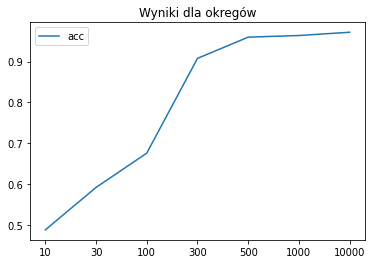

In [32]:
exp_data = experimetnt_layers_hidden()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc"]].plot()
xticklabels = ["10", "30", "100", "300", "500", "1000", "10000"]
plt.title('Wyniki dla okregów')
plt.xticks([0, 1, 2, 3, 4, 5, 6], xticklabels)
plt.show()

  solver  layers_count  layers_size    acc  acc_train        f1       auc  \
0  lbfgs             1           10  0.582      0.608  0.132780  0.573851   
1  lbfgs             1           30  0.618      0.638  0.300366  0.665616   
2  lbfgs             1          100  0.636      0.686  0.515957  0.751790   
3  lbfgs             1          300  0.740      0.718  0.690476  0.829059   
4  lbfgs             1          500  0.750      0.764  0.724062  0.848469   
5  lbfgs             1         1000  0.804      0.790  0.784141  0.881196   
6  lbfgs             1        10000  0.850      0.826  0.838013  0.928242   

   n_params  
0        41  
1       121  
2       401  
3      1201  
4      2001  
5      4001  
6     40001  


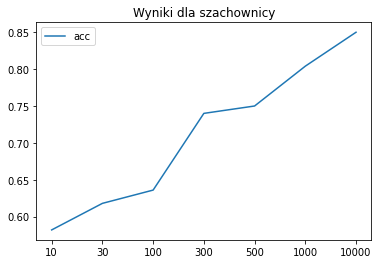

In [34]:
exp_data = experimetnt_layers_hidden()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc"]].plot()
xticklabels = ["10", "30", "100", "300", "500", "1000", "10000"]
plt.title('Wyniki dla szachownicy')
plt.xticks([0, 1, 2, 3, 4, 5, 6], xticklabels)
plt.show()

**Wniosek :** _Zwiększanie liczby neuronów w warstwie sieci zwiększa jakość modelu._ 

**Eksperyment dla rozmiarów danych uczących alfa = 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5**

In [57]:
def experiment_alfa_size():
#     X, y = make_circles(n_samples=1000, noise=0.05)
    X, y = make_checkerboard(1000,3, noise=.1)
    
    train_sizes = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]

    data = {
        "train_size": [],
        "acc": [],
        "acc_train": [],
        "f1": [],
        "auc": [],
        "t_fit": [],
        "t_pred": [],
    }

    for train_size in train_sizes:
        X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42)

        clf = MLPClassifier(hidden_layer_sizes=500, solver="adam", alpha=1e-5)
        clf.fit(X_train, y_train)

        y_true = y_test
        y_pred = clf.predict(X_test)

        acc = accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)

        y_score = clf.predict_proba(X_test)
        auc = roc_auc_score(y_true, y_score[:, 1])

        acc_train = accuracy_score(y_train, clf.predict(X_train))

        t1_fit = time.time()
        clf.fit(X_train, y_train)
        t_fit = time.time() - t1_fit

        t1_pred = time.time()
        clf.predict(X_test)
        t_pred = time.time() - t1_pred

        data["train_size"].append(train_size)
        data["acc"].append(acc)
        data["acc_train"].append(acc_train)
        data["f1"].append(f1)
        data["auc"].append(auc)
        data["t_fit"].append(t_fit)
        data["t_pred"].append(t_pred)
            
    return data

   train_size       acc  acc_train        f1       auc     t_fit    t_pred
0       0.001  0.499499      1.000  0.000000  0.502653  0.122778  0.002571
1       0.002  0.504008      1.000  0.539535  0.502311  0.138885  0.002443
2       0.005  0.503518      1.000  0.543438  0.499467  0.145091  0.002270
3       0.010  0.565657      1.000  0.683824  0.485123  0.154427  0.002276
4       0.020  0.641837      0.900  0.664756  0.691804  0.197880  0.002479
5       0.050  0.718947      0.920  0.732197  0.778694  0.253412  0.002203
6       0.100  0.908889      0.950  0.909292  0.974637  0.495691  0.002310
7       0.200  0.918750      0.945  0.919054  0.981993  0.538995  0.001914
8       0.500  0.974000      0.976  0.974560  0.996270  1.460054  0.001391


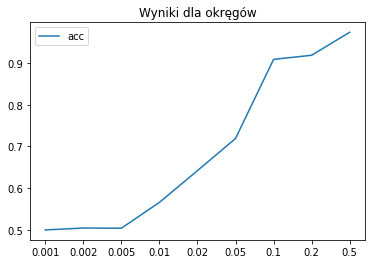

In [56]:
exp_data = experiment_alfa_size()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc"]].plot()
xticklabels = ["0.001", "0.002", "0.005", "0.01", "0.02", "0.05", "0.1", "0.2", "0.5"]
plt.title('Wyniki dla okręgów')
plt.xticks([0, 1, 2, 3, 4, 5, 6, 7, 8], xticklabels)
plt.show()

   train_size       acc  acc_train        f1       auc     t_fit    t_pred
0       0.001  0.546547      1.000  0.000000  0.492039  0.094965  0.002329
1       0.002  0.509018      1.000  0.635958  0.509498  0.138872  0.002282
2       0.005  0.515578      1.000  0.505133  0.515990  0.144382  0.004714
3       0.010  0.549495      0.800  0.254181  0.582160  0.158800  0.002518
4       0.020  0.690816      0.950  0.578581  0.667712  0.205594  0.002256
5       0.050  0.696842      0.820  0.671982  0.768157  0.467395  0.010345
6       0.100  0.666667      0.760  0.605263  0.765387  0.384419  0.002117
7       0.200  0.713750      0.745  0.695073  0.766065  0.863085  0.001885
8       0.500  0.820000      0.824  0.810924  0.888969  1.979036  0.001570


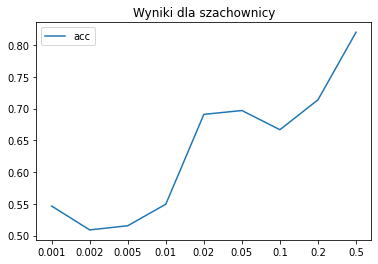

In [58]:
exp_data = experiment_alfa_size()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc"]].plot()
xticklabels = ["0.001", "0.002", "0.005", "0.01", "0.02", "0.05", "0.1", "0.2", "0.5"]
plt.title('Wyniki dla szachownicy')
plt.xticks([0, 1, 2, 3, 4, 5, 6, 7, 8], xticklabels)
plt.show()

**Wniosek :** _Zwiększanie wielkości rozmiaru danych uczących w warstwie sieci powoduje zwiększa jakość modelu._ 

**Eksperyment dla parametru regularyzacyjnego alfa = 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 1e1, 1e2**

In [66]:
def experiment_alfa_reg():
    X, y = make_circles(n_samples=1000, noise=0.05)
#     X, y = make_checkerboard(1000,3, noise=.1)

    data = {
        "alpha": [],
        "acc": [],
        "acc_train": [],
        "f1": [],
        "auc": [],
        "n_params": [],
        "t_fit": [],
    }
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=.5, random_state=10)

    for alpha in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 1e0, 1e1, 1e2]:
        clf = MLPClassifier(hidden_layer_sizes=1000, solver="adam", alpha=1e-5)
        t1_fit = time.time()
        clf.fit(X_train, y_train)
        t_fit = time.time() - t1_fit

        # Parametry jakie obserwujemt
        y_true = y_test
        y_pred = clf.predict(X_test)

        acc = accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)

        y_score = clf.predict_proba(X_test)
        auc = roc_auc_score(y_true, y_score[:, 1])

        acc_train = accuracy_score(y_train, clf.predict(X_train))

        n_params = sum([a.size for a in clf.coefs_]) + sum([a.size for a in clf.intercepts_])
        data["alpha"].append(alpha)
        data["acc"].append(acc)
        data["acc_train"].append(acc_train)
        data["f1"].append(f1)
        data["auc"].append(auc)
        data["t_fit"].append(t_fit)
        data["n_params"].append(n_params)
        
    return data

       alpha    acc  acc_train        f1       auc  n_params     t_fit
0    0.00001  0.974      0.984  0.971678  0.994589      4001  3.419881
1    0.00010  0.972      0.980  0.969697  0.994750      4001  2.773832
2    0.00100  0.964      0.980  0.960352  0.994783      4001  3.035929
3    0.01000  0.972      0.982  0.969565  0.994783      4001  3.211817
4    0.10000  0.970      0.978  0.967603  0.994944      4001  2.285728
5    1.00000  0.970      0.980  0.967320  0.994573      4001  2.355561
6    1.00000  0.970      0.976  0.967320  0.994702      4001  2.304081
7   10.00000  0.972      0.984  0.969565  0.994589      4001  2.516536
8  100.00000  0.974      0.978  0.971800  0.995056      4001  2.356820


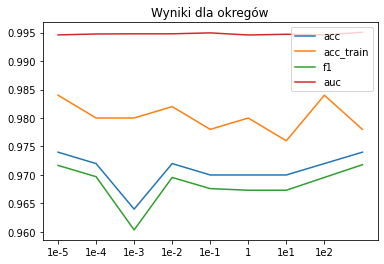

In [67]:
exp_data = experiment_alfa_reg()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc", "acc_train", "f1", "auc"]].plot()
xticklabels = ["1e-5", "1e-4", "1e-3", "1e-2", "1e-1", "1", "1e1", "1e2"]
plt.title('Wyniki dla okregów')
plt.xticks([0, 1, 2, 3, 4, 5, 6, 7], xticklabels)
plt.show()

       alpha    acc  acc_train        f1       auc  n_params     t_fit
0    0.00001  0.780      0.804  0.754464  0.879291      4001  2.421629
1    0.00010  0.782      0.816  0.765591  0.883746      4001  2.316557
2    0.00100  0.780      0.812  0.762931  0.880536      4001  2.247988
3    0.01000  0.788      0.814  0.763393  0.881093      4001  2.308490
4    0.10000  0.782      0.814  0.769556  0.889315      4001  2.293543
5    1.00000  0.776      0.818  0.763713  0.879766      4001  2.343940
6    1.00000  0.782      0.806  0.767591  0.878800      4001  2.267620
7   10.00000  0.788      0.816  0.767544  0.884025      4001  2.314181
8  100.00000  0.788      0.812  0.765487  0.881338      4001  2.295140


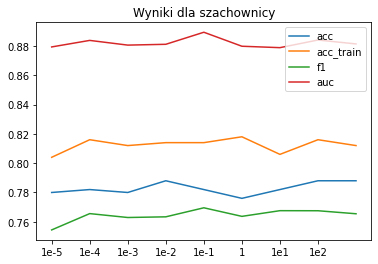

In [65]:
exp_data = experiment_alfa_reg()    
df = pd.DataFrame(exp_data)
print(df)
df.loc[:, ["acc", "acc_train", "f1", "auc"]].plot()
xticklabels = ["1e-5", "1e-4", "1e-3", "1e-2", "1e-1", "1", "1e1", "1e2"]
plt.title('Wyniki dla szachownicy')
plt.xticks([0, 1, 2, 3, 4, 5, 6, 7], xticklabels)
plt.show()

**Wniosek :** _Zwiększanie parametru regularyzacyjnego **alfa** nieznacznie wpływa na zwiększenie jakość modelu. Zwiększenie parametru regularyzacyjnego skraca również czas uczenia._ 